# glitch_results1.csv
gc.set_range("tries", 1, 2)
gc.set_step("tries", 1)
gc.set_range("ext_offset", 1000, 1100)  # 1000 - 1100 
gc.set_step("ext_offset", 10)
#gc.set_range("width", 2000, 2800)       # 2800 reset  2700 ok
gc.set_range("width", 2200, 2800)       # 2800 reset  2700 ok
gc.set_step("width", 50)
gc.set_range("offset", -2800, 2800)
gc.set_step("offset", 20)


In [ ]:
%matplotlib widget
%run ./LibStm32Boot.ipynb
%run ./LibLoadSaveSettings.ipynb
%run ./LibLogicAnalyserGlitchTools.ipynb

import numpy as np
import matplotlib.pyplot as plt
import struct, csv, os, time
import datetime
import sys

FLASH_SIZE = 256      # test
CHUNK = 64                   # SAM3U RX buffer holds only 128-200 bytes
BAUD = 115200
BYTE_GAP = 0.0001              # back-to-back bytes get NACKed by the bootloader
RETRIES = 3
debug=False

out_path = "flash_dump.bin"
size = FLASH_SIZE

try:
    scope.dis()
except:
    pass
try:
    fig1.dis()
except:
    pass
try:
    fig2.dis()
except:
    pass

def init_logic_analyser(scope, glitch=True, capture_group='CW 20-pin'):
    scope.errors.clear()
    scope.adc.segments = 1
    scope.gain.db = 25

    scope.io.hs2 = 'glitch'              # Glitch on HS2, for example to feed an external device
    scope.io.glitch_trig_mcx = 'glitch' # Glitch pulse on the Trigger/Glitch Out MCX connector
    scope.io.tio1 = "serial_tx"
    scope.io.tio2 = "serial_rx"
    scope.io.tio3 = "gpio_high"

    scope.trigger.module = "basic"
    scope.trigger.triggers = "tio1"
    scope.glitch.trigger_src = "ext_single"   # glitch also fires on that trigger

    scope.adc.basic_mode = "falling_edge"   # catch the actual start bit
    scope.adc.presamples = 0
    scope.adc.samples = 10
    scope.adc.lo_gain_errors_disabled = True
    
    # --- Logic analyzer: record trigger + glitch signals ---
    scope.LA.enabled = True
    scope.LA.capture_group = capture_group
    scope.LA.capture_depth = 40000
    scope.LA.trigger_source = 'capture'     
    scope.LA.oversampling_factor = 1
    scope.LA.downsample = 1   # try 100 to 1000 until you see the whole exchange

    if glitch:
        scope.glitch.enabled = True
        scope.io.glitch_hp = True
        scope.io.glitch_lp = True
    else:
        scope.glitch.enabled = False
        scope.io.glitch_hp = False
        scope.io.glitch_lp = False

    scope.glitch.clk_src = 'pll'
    #scope.glitch.output = "enable_only"  # one large glitch repeat times
    scope.glitch.output = "glitch_only" # multiple short (width) glitches
    


scope = cw.scope()
scope.default_setup(verbose=False)
target = cw.target(scope, cw.targets.SimpleSerial)
set_debug_pin(True)

scope.clock.clkgen_freq = 6e6
assert scope.clock.clkgen_locked
ser = target.ser
ser.setBaud(BAUD)
ser.setParity("even")

init_logic_analyser(scope)


enter_bootloader()

# Get ID as a sanity check (expect 0462 for the L45x family)
get_product_id()

def bump_counter(gc, group):
    idx = gc.groups.index(group)
    gc.widget_list_groups[idx].value += 1

def trigger_operation(gc, settings):
    data = []
    #print("trigger_operation")
    try:
        data = read_mem(addr=FLASH_BASE, length=256)
    except Exception as e:
        if "NACK" in str(e):
            gc.add("normal", settings)
            log_result("normal")
            bump_counter(gc, "normal")
            #print("normal")
        elif "Reset" in str(e):
            gc.add("reset", settings)
            log_result("reset")
            bump_counter(gc, "reset")
        else:
            gc.add("reset", settings)
            log_result("reset")
            bump_counter(gc, "reset")
        return data

    if not data or len(data) < expected_length:
        gc.add("error", settings)
        log_result("error")
        bump_counter(gc, "error")
    else:
        gc.add("success", settings)
        log_result("success")
        bump_counter(gc, "success")
    return data

    

def pre_arm_action(scope):
    pass

def post_arm_trigger_action(scope):
    trigger_operation()

def post_capture_action(scope):
    pass


def capture_with_la(scope, gc, capture_group, addr=FLASH_BASE, length=256,
                     ext_offset=10, offset=0, width=3000, repeat=1, tries=1,
                     trigger='trigger_glitch', with_la=False):
    scope.errors.clear()

    # 1. Set glitch params FIRST (this is what perturbs the shared PLL)
    scope.glitch.offset = offset
    scope.glitch.ext_offset = ext_offset
    scope.glitch.width = width
    scope.glitch.repeat = repeat

    # 2. THEN re-specify the LA clock, now that the PLL has settled
    if with_la:
        scope.LA.capture_group = capture_group
        for attempt in range(3):
            scope.LA.enabled = False
            scope.LA.oversampling_factor = 1
            scope.LA.enabled = True
            if scope.LA.locked:
                break
            time.sleep(0.01)
        else:
            raise RuntimeError("LA clock would not lock after 3 attempts")

    ser.flush()
    time.sleep(0.01)
    if with_la:
        scope.LA.arm()   
    scope.arm()
    #print("scope.glitch.mmcm_locked ", scope.glitch.mmcm_locked)
    time.sleep(0.003)
    settings = (width, offset, ext_offset, tries)
    data = trigger_operation(gc, settings)
    
    
    res=None
    if with_la:
        res = read_capture_data(scope)

    scope.LA.enabled = False
    return res, data



off=0
addr = FLASH_BASE + off
length = min(CHUNK, size - off)

MAX_SUCCESSES = 100
LOGFILE = "glitch_results.csv"
n_written = 0

gc = cw.GlitchController(groups=["success", "reset", "normal", "error"], parameters=["width", "offset", "ext_offset", "tries"])
gc.display_stats()
#gc.glitch_plot(plotdots={"success":"|g", "reset":"_r", "normal":None})

gc.set_global_step(1)                 # must come before any set_step(...)
gc.set_range("tries", 1, 10)
gc.set_step("tries", 1)
gc.set_range("ext_offset", 1000, 1100)  # 1000 - 1100 
gc.set_step("ext_offset", 1)
gc.set_range("width", 2300, 2450)       
gc.set_step("width", 10)
gc.set_range("offset", -2800, 2800)
gc.set_step("offset", 20)


print("start ", str(datetime.datetime.now()))
#print("total glitch settings:", sum(1 for _ in gc.glitch_values()))
#sys.exit(0)

def settings_tuple():
    return (scope.glitch.width, scope.glitch.offset, scope.glitch.ext_offset)


with open(LOGFILE, "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["width", "offset", "ext_offset", "result"])

    def log_result(result):
        global n_written
        #print("log ", n_written)
        w, o, e = settings_tuple()
        writer.writerow([w, o, e, result])
        n_written += 1
        if n_written % 100 == 0:       # flush regularly so nothing is lost on a crash
            f.flush()
            os.fsync(f.fileno())
    
    try:
        for i, glitch_setting in enumerate(gc.glitch_values()):
            offset=offset = glitch_setting[1]
            width = glitch_setting[0]
            ext_offset = glitch_setting[2]
            tries = glitch_setting[3]
            #print(f"width:{width} offset:{offset} ext_offset:{ext_offset} tries:{tries}")
            try:
                res, data = capture_with_la(scope, gc, 'CW 20-pin', addr, length, ext_offset=ext_offset, width=width, offset=offset, tries=tries)
            
                #print("scope.clock", scope.clock)
                #print("scope.LA", scope.LA)
            except Exception as e:
                #print(f"Exception on {width}/{offset}/{ext_offset}: {e}")
                print(e, " scope.LA.locked " ,scope.LA.locked, " scope.clock.clkgen_locked ", scope.clock.clkgen_locked)
                continue
                
            #fig1 = plot_la_interactive(res, title=caption(calc_glitch_times(scope)))
    except Exception as e:
        print(f"Exception: {e}")
    finally:
        f.flush()
        os.fsync(f.fileno())


print("finished ", str(datetime.datetime.now()))

scope.dis()
scope = None


IntText(value=0, description='success count:', disabled=True)

IntText(value=0, description='reset count:', disabled=True)

IntText(value=0, description='normal count:', disabled=True)

IntText(value=0, description='error count:', disabled=True)

FloatSlider(value=0.0, continuous_update=False, description='width setting:', disabled=True, max=10.0, readout…

FloatSlider(value=0.0, continuous_update=False, description='offset setting:', disabled=True, max=10.0, readou…

FloatSlider(value=0.0, continuous_update=False, description='ext_offset setting:', disabled=True, max=10.0, re…

FloatSlider(value=0.0, continuous_update=False, description='tries setting:', disabled=True, max=10.0, readout…

start  2026-11-26 14:44:31.135782


result
reset     61713
normal    18653
Name: count, dtype: int64


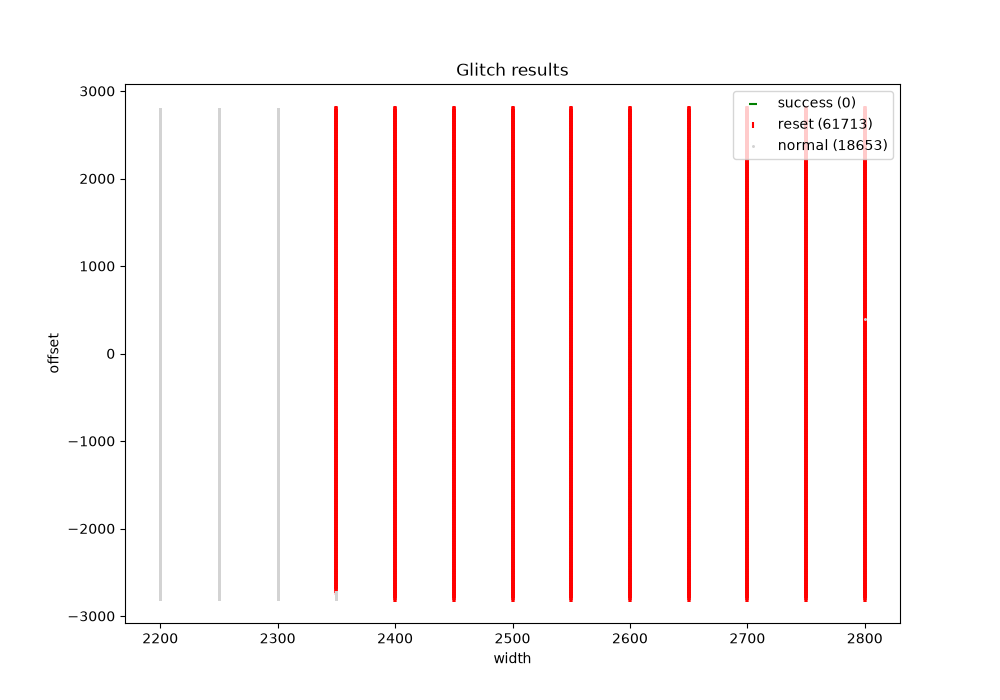

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("glitch_results.csv")
print(df["result"].value_counts())

styles = {
    "success": dict(marker="_", color="g", s=40),
    "reset":   dict(marker="|", color="r", s=15),
    "normal": dict(marker=".", color="lightgray", s=5),   # uncomment to show normal runs
}

fig, ax = plt.subplots(figsize=(10, 7))
for res, kw in styles.items():
    sub = df[df["result"] == res]
    ax.scatter(sub["width"], sub["offset"], label=f"{res} ({len(sub)})", **kw)
ax.set_xlabel("width"); ax.set_ylabel("offset"); ax.legend()
ax.set_title("Glitch results")
plt.show()

# if you sweep ext_offset, plot one slice at a time, e.g.:
# sub = df[df["ext_offset"] == 123]